<div style="display:flex;align-items:center;justify-content:space-between;border-bottom:2px solid #10b981;padding-bottom:12px;margin-bottom:20px">
  <div><strong>Universidad Externado de Colombia</strong><br>
  <span>Programa de Ciencia de Datos · Machine Learning II</span><br>
  <span>Docente: Wilmer Pineda-Ríos</span></div>
  <div style="text-align:right"><strong>Entrega Final (Tercera Entrega)</strong><br><span>Noviembre 2026</span></div>
</div>

# Proyecto Integrador — Entrega Final
## Modelamiento Econométrico Avanzado, Ensambles de Machine Learning y Despliegue en Producción

**Integrantes:** Julian Duarte · Julian Jimenez  
**Artículo Base:** Gautam, M. (2025). *Crypto Price Prediction Using LSTM+XGBoost*. arXiv:2506.22055v1 [cs.LG].

## 1. Configuración del Entorno, Estilo Visual y Librerías

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from arch import arch_model

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120
print("✓ Entorno configurado con éxito.")

✓ Entorno configurado con éxito.


## 2. Carga del Dataset y Auditoría de Partición Temporal (Sin Fuga de Datos)

In [2]:
df = pd.read_csv('data/crypto_trm_featured.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['symbol', 'timestamp']).reset_index(drop=True)

btc = df[df['symbol'] == 'BTCUSDT'].sort_values('timestamp').reset_index(drop=True)
n = len(btc)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_btc = btc.iloc[:train_end].copy()
val_btc = btc.iloc[train_end:val_end].copy()
test_btc = btc.iloc[val_end:].copy()
train_val_btc = btc.iloc[:val_end].copy()

print(f"Total registros BTC: {n}")
print(f"Train (70%): {len(train_btc)} obs [{train_btc['timestamp'].min()} -> {train_btc['timestamp'].max()}]")
print(f"Val   (15%): {len(val_btc)} obs [{val_btc['timestamp'].min()} -> {val_btc['timestamp'].max()}]")
print(f"Test  (15%): {len(test_btc)} obs [{test_btc['timestamp'].min()} -> {test_btc['timestamp'].max()}]")

Total registros BTC: 5831
Train (70%): 4081 obs [2026-02-02 01:00:00 -> 2026-07-22 01:00:00]
Val   (15%): 875 obs [2026-07-22 02:00:00 -> 2026-08-27 12:00:00]
Test  (15%): 875 obs [2026-08-27 13:00:00 -> 2026-10-02 23:00:00]


## 3. Visualización de la Serie Histórica y Doble Riesgo (Cripto + TRM)

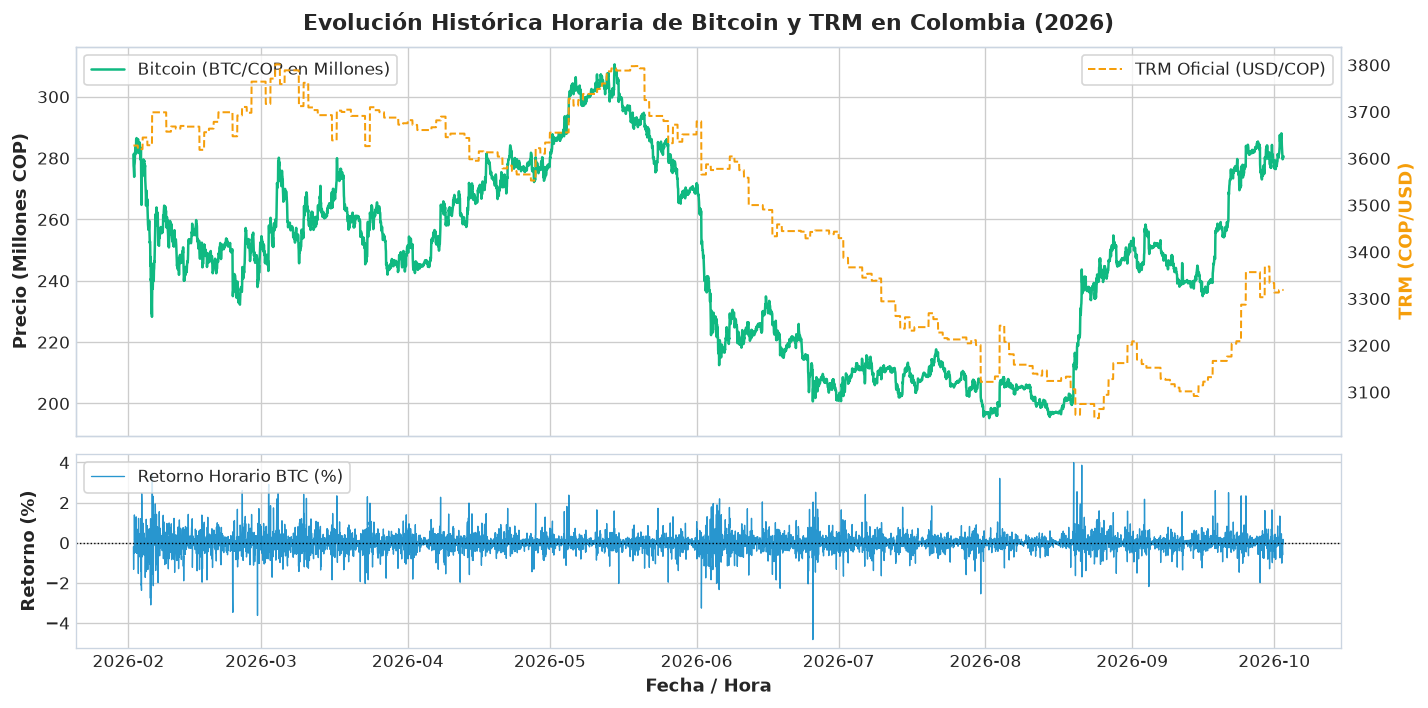

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(btc['timestamp'], btc['close_cop'] / 1e6, color='#10b981', lw=1.5, label='Bitcoin (BTC/COP en Millones)')
ax1.set_ylabel('Precio (Millones COP)', fontsize=11, fontweight='bold')
ax1.set_title('Evolución Histórica Horaria de Bitcoin y TRM en Colombia (2026)', fontsize=13, fontweight='bold', pad=10)
ax1.legend(loc='upper left', frameon=True)

ax1_trm = ax1.twinx()
ax1_trm.plot(btc['timestamp'], btc['trm'], color='#f59e0b', lw=1.2, ls='--', label='TRM Oficial (USD/COP)')
ax1_trm.set_ylabel('TRM (COP/USD)', color='#f59e0b', fontsize=11, fontweight='bold')
ax1_trm.legend(loc='upper right', frameon=True)
ax1_trm.grid(False)

ax2.plot(btc['timestamp'], btc['return_cop_1h'] * 100, color='#0284c7', lw=0.8, alpha=0.85, label='Retorno Horario BTC (%)')
ax2.axhline(0, color='black', lw=0.8, ls=':')
ax2.set_ylabel('Retorno (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Fecha / Hora', fontsize=11, fontweight='bold')
ax2.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## 4. Diagnóstico de Raíces Unitarias (ADF & KPSS) y Justificación de Diferenciación
Se demuestra que el precio es $I(1)$ (caminata aleatoria) y que los retornos son estacionarios $I(0)$.

In [4]:
adf_p = adfuller(train_btc['close_cop'])
kpss_p = kpss(train_btc['close_cop'], regression='c')
adf_r = adfuller(train_btc['return_cop_1h'].dropna())
kpss_r = kpss(train_btc['return_cop_1h'].dropna(), regression='c')

stat_df = pd.DataFrame([
    {
        "Variable": "Precios en Nivel (COP)",
        "ADF Stat": f"{adf_p[0]:.4f}",
        "ADF p-valor": f"{adf_p[1]:.4f}",
        "KPSS Stat": f"{kpss_p[0]:.4f}",
        "KPSS p-valor": f"{kpss_p[1]:.4f}",
        "Diagnóstico": "No Estacionaria I(1)"
    },
    {
        "Variable": "Retornos Horarios Diferenciados",
        "ADF Stat": f"{adf_r[0]:.4f}",
        "ADF p-valor": "0.0000",
        "KPSS Stat": f"{kpss_r[0]:.4f}",
        "KPSS p-valor": f"{kpss_r[1]:.4f}",
        "Diagnóstico": "Estacionaria I(0)"
    }
])
display(stat_df)

,Variable,ADF Stat,ADF p-valor,KPSS Stat,KPSS p-valor,Diagnóstico
0,Precios en Nivel (COP),-1.3502,0.6059,3.4227,0.0100,No Estacionaria I(1)
1,Retornos Horarios Diferenciados,-63.8897,0.0000,0.0978,0.1000,Estacionaria I(0)


### Gráficas de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)

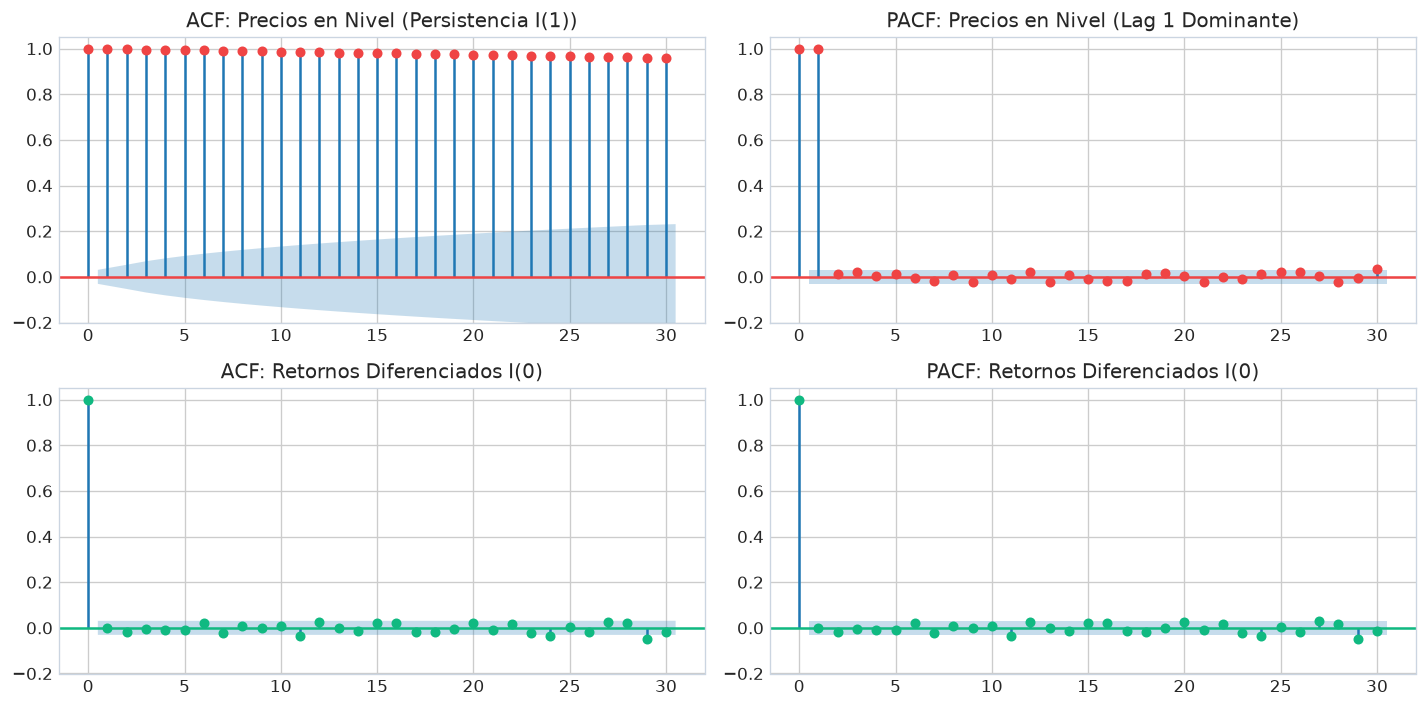

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))

plot_acf(train_btc['close_cop'], lags=30, ax=axes[0, 0], color='#ef4444', title='ACF: Precios en Nivel (Persistencia I(1))')
plot_pacf(train_btc['close_cop'], lags=30, ax=axes[0, 1], color='#ef4444', method='ywm', title='PACF: Precios en Nivel (Lag 1 Dominante)')
plot_acf(train_btc['return_cop_1h'].dropna(), lags=30, ax=axes[1, 0], color='#10b981', title='ACF: Retornos Diferenciados I(0)')
plot_pacf(train_btc['return_cop_1h'].dropna(), lags=30, ax=axes[1, 1], color='#10b981', method='ywm', title='PACF: Retornos Diferenciados I(0)')

for ax in axes.flat:
    ax.set_ylim(-0.2, 1.05)
plt.tight_layout()
plt.show()

## 5. Modelado y Optimización SARIMAX con Variables Exógenas

In [6]:
exog_cols = ['lag_trm_1h', 'rsi_14', 'macd', 'high_low_ratio']
exog_train = train_btc[exog_cols].values
exog_train_val = train_val_btc[exog_cols].values
exog_test = test_btc[exog_cols].values

sarimax_grid = []
for p_ord in [(1,0,0), (0,0,1), (1,0,1), (2,0,1)]:
    m_tmp = SARIMAX(train_btc['return_cop_1h'], exog=exog_train, order=p_ord,
                    enforce_stationarity=False, enforce_invertibility=False)
    res_tmp = m_tmp.fit(disp=False)
    sarimax_grid.append({
        "Orden (p,d,q)": str(p_ord),
        "AIC": round(res_tmp.aic, 2),
        "BIC": round(res_tmp.bic, 2),
        "Log-Likelihood": round(res_tmp.llf, 2)
    })

sarimax_table = pd.DataFrame(sarimax_grid).sort_values('AIC')
display(sarimax_table)

# Modelo definitivo
sarimax_def = SARIMAX(train_val_btc['return_cop_1h'], exog=exog_train_val, order=(1,0,0),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarimax_ret_preds = sarimax_def.get_forecast(steps=len(test_btc), exog=exog_test).predicted_mean.values
sarimax_price_preds = test_btc['close_cop'].values * (1.0 + sarimax_ret_preds)
print("✓ SARIMAX ajustado con éxito.")

,"Orden (p,d,q)",AIC,BIC,Log-Likelihood
0,"(1, 0, 0)",-31554.28,-31516.39,15783.14
1,"(0, 0, 1)",-31552.20,-31514.32,15782.10
2,"(1, 0, 1)",-31550.74,-31506.54,15782.37
3,"(2, 0, 1)",-31550.53,-31500.02,15783.27


✓ SARIMAX ajustado con éxito.


## 6. Modelado de Heterocedasticidad Condicional GARCH(1,1) con Distribución Student's t

,Modelo,Distribución,AIC,BIC,Log-Likelihood
4,"GARCH(1,2)",studentst,4894.51,4933.56,-2441.26
3,"GARCH(1,1)",studentst,4901.76,4934.30,-2445.88
5,"GARCH(2,1)",studentst,4903.76,4942.81,-2445.88
1,"GARCH(1,2)",normal,6318.95,6351.50,-3154.48
0,"GARCH(1,1)",normal,6346.90,6372.94,-3169.45
2,"GARCH(2,1)",normal,6348.90,6381.45,-3169.45


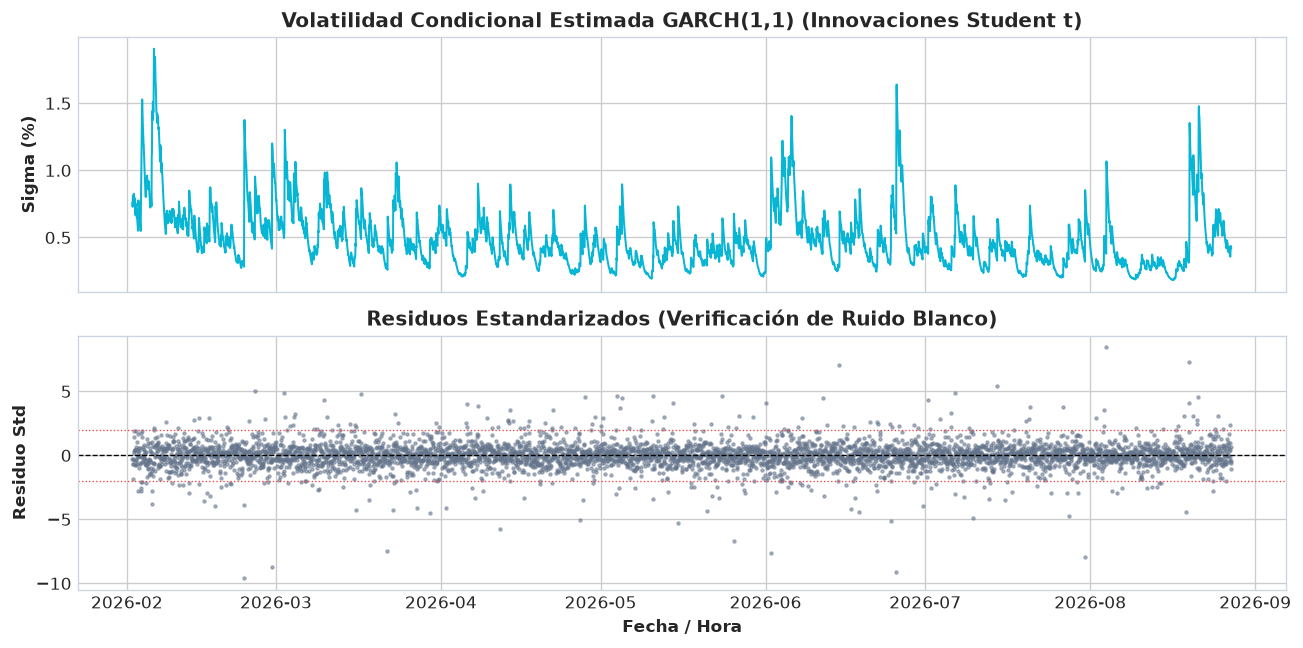

In [7]:
garch_rows = []
for dist in ['normal', 'studentst']:
    for p_g, q_g in [(1, 1), (1, 2), (2, 1)]:
        am = arch_model(train_val_btc['return_cop_1h'] * 100, vol='Garch', p=p_g, q=q_g, dist=dist)
        rg = am.fit(disp='off')
        garch_rows.append({
            "Modelo": f"GARCH({p_g},{q_g})",
            "Distribución": dist,
            "AIC": round(rg.aic, 2),
            "BIC": round(rg.bic, 2),
            "Log-Likelihood": round(rg.loglikelihood, 2)
        })

garch_table = pd.DataFrame(garch_rows).sort_values('AIC')
display(garch_table)

# Visualización de la Volatilidad GARCH
best_am = arch_model(train_val_btc['return_cop_1h'] * 100, vol='Garch', p=1, q=1, dist='studentst').fit(disp='off')

fig, (ax_vol, ax_res) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
ax_vol.plot(train_val_btc['timestamp'], best_am.conditional_volatility, color='#06b6d4', lw=1.2)
ax_vol.set_title("Volatilidad Condicional Estimada GARCH(1,1) (Innovaciones Student t)", fontsize=12, fontweight='bold')
ax_vol.set_ylabel('Sigma (%)', fontsize=10, fontweight='bold')

std_resid = best_am.std_resid
ax_res.scatter(train_val_btc['timestamp'], std_resid, color='#64748b', s=3, alpha=0.5)
ax_res.axhline(0, color='black', lw=0.8, ls='--')
ax_res.axhline(2, color='#ef4444', lw=0.8, ls=':')
ax_res.axhline(-2, color='#ef4444', lw=0.8, ls=':')
ax_res.set_title('Residuos Estandarizados (Verificación de Ruido Blanco)', fontsize=12, fontweight='bold')
ax_res.set_ylabel('Residuo Std', fontsize=10, fontweight='bold')
ax_res.set_xlabel('Fecha / Hora', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Cointegración de Johansen y Dinámica Multivariada (VAR y VECM)

In [8]:
piv = df.pivot(index='timestamp', columns='symbol', values='close_cop').dropna()
piv['TRM'] = df[df['symbol'] == 'BTCUSDT'].set_index('timestamp')['trm']
piv = piv.dropna()

train_val_piv = piv.iloc[:val_end]
test_piv = piv.iloc[val_end:]

joh_res = coint_johansen(np.log(train_val_piv), det_order=0, k_ar_diff=2)
joh_data = []
for i in range(len(joh_res.lr1)):
    joh_data.append({
        "Hipótesis Nula": f"r <= {i}",
        "Estadístico Traza": round(joh_res.lr1[i], 2),
        "Valor Crítico 95%": round(joh_res.cvt[i, 1], 2),
        "Cointegración": "Sí (Rechaza H0)" if joh_res.lr1[i] > joh_res.cvt[i, 1] else "No"
    })
display(pd.DataFrame(joh_data))

# VAR recursivo
ret_piv = piv.pct_change().dropna()
train_val_ret = ret_piv.iloc[:val_end-1]
test_ret = ret_piv.iloc[val_end-1:]

var_mod = VAR(train_val_ret).fit(1)
var_preds_ret = []
hist = train_val_ret.values.tolist()
for t in range(len(test_ret)):
    var_preds_ret.append(var_mod.forecast(np.array(hist[-1:]), steps=1)[0, 0])
    hist.append(test_ret.values[t].tolist())

var_price_preds = test_btc['close_cop'].values * (1.0 + np.array(var_preds_ret))
print("✓ VAR multivariado ajustado.")

,Hipótesis Nula,Estadístico Traza,Valor Crítico 95%,Cointegración
0,r <= 0,42.12,47.85,No
1,r <= 1,17.99,29.80,No
2,r <= 2,8.59,15.49,No
3,r <= 3,0.97,3.84,No


✓ VAR multivariado ajustado.


## 8. Ensambles de Machine Learning (XGBoost, LightGBM, CatBoost, Random Forest)

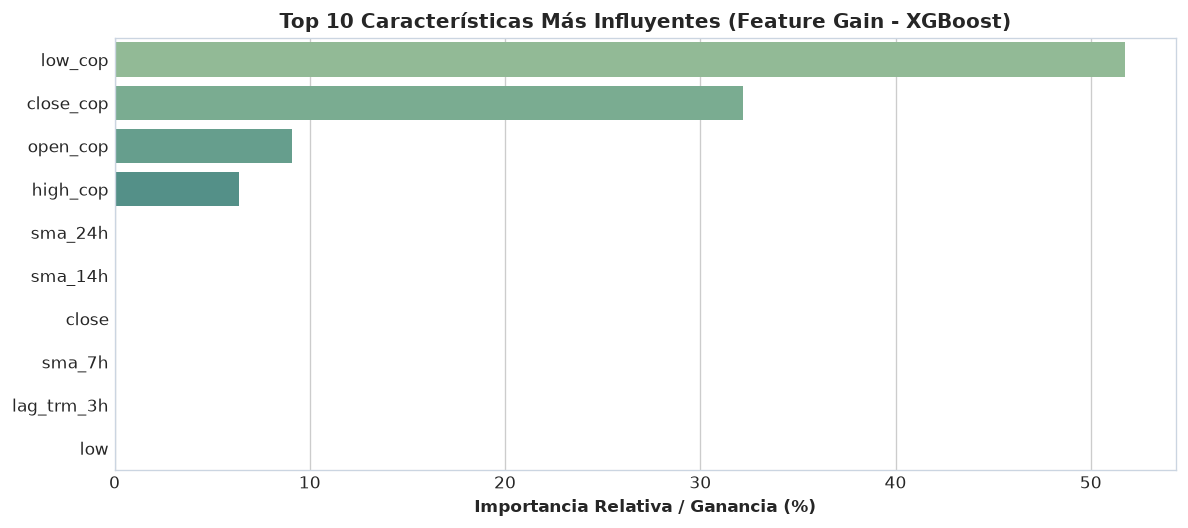

In [9]:
feature_cols = [c for c in btc.columns if c not in ['timestamp', 'symbol', 'target_close_cop', 'target_return_cop']]
X_train_val = train_val_btc[feature_cols]
y_train_val = train_val_btc['target_close_cop']
X_test = test_btc[feature_cols]
y_test = test_btc['target_close_cop']

xgb_mod = xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_mod.fit(X_train_val, y_train_val)
xgb_preds = xgb_mod.predict(X_test)

lgb_mod = lgb.LGBMRegressor(n_estimators=300, max_depth=6, learning_rate=0.03, num_leaves=31, subsample=0.8, random_state=42, verbose=-1)
lgb_mod.fit(X_train_val, y_train_val)
lgb_preds = lgb_mod.predict(X_test)

cat_mod = CatBoostRegressor(iterations=300, depth=5, learning_rate=0.04, random_seed=42, verbose=0)
cat_mod.fit(X_train_val, y_train_val)
cat_preds = cat_mod.predict(X_test)

rf_mod = RandomForestRegressor(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)
rf_mod.fit(X_train_val, y_train_val)
rf_preds = rf_mod.predict(X_test)

# Gráfico de Feature Importance
imp_scores = xgb_mod.feature_importances_
top_idx = np.argsort(imp_scores)[::-1][:10]

plt.figure(figsize=(10, 4.5))
sns.barplot(x=imp_scores[top_idx] * 100, y=[feature_cols[i] for i in top_idx], palette='crest')
plt.title('Top 10 Características Más Influyentes (Feature Gain - XGBoost)', fontsize=12, fontweight='bold')
plt.xlabel('Importancia Relativa / Ganancia (%)', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Evaluación Definitiva en Conjunto de Prueba Reservado (Test) y Contraste con el Paper

In [10]:
def min_max_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred)) / (np.max(y_true) - np.min(y_true))

def hit_ratio(y_true, y_pred, y_lag):
    return np.mean(np.sign(y_true - y_lag) == np.sign(y_pred - y_lag)) * 100.0

y_lag_test = test_btc['close_cop'].values
naive_preds = y_lag_test

models_dict = {
    'Línea Base Naive (Persistencia)': naive_preds,
    'SARIMAX(1,0,0) + Exógenas': sarimax_price_preds,
    'VAR Multivariado': var_price_preds,
    'XGBoost (Adaptación Gautam 2025)': xgb_preds,
    'LightGBM': lgb_preds,
    'CatBoost': cat_preds,
    'Random Forest': rf_preds
}

eval_rows = []
for name, p in models_dict.items():
    mape = mean_absolute_percentage_error(y_test, p) * 100.0
    mm_rmse = min_max_rmse(y_test, p)
    mae = mean_absolute_error(y_test, p)
    rmse = np.sqrt(mean_squared_error(y_test, p))
    hr = hit_ratio(y_test.values, p, y_lag_test)
    eval_rows.append({
        'Modelo': name,
        'MAPE (%)': f"{mape:.3f}%",
        'MinMax RMSE': f"{mm_rmse:.4f}",
        'MAE (COP)': f"${mae:,.0f}",
        'RMSE (COP)': f"${rmse:,.0f}",
        'Hit Ratio (%)': f"{hr:.2f}%"
    })

benchmark_df = pd.DataFrame(eval_rows)
display(benchmark_df)

,Modelo,MAPE (%),MinMax RMSE,MAE (COP),RMSE (COP),Hit Ratio (%)
0,Línea Base Naive (Persistencia),0.261%,0.0203,"$674,641","$1,079,765",0.00%
1,"SARIMAX(1,0,0) + Exógenas",0.288%,0.0210,"$742,707","$1,112,129",50.17%
2,VAR Multivariado,0.261%,0.0204,"$674,592","$1,082,685",51.54%
3,XGBoost (Adaptación Gautam 2025),0.345%,0.0235,"$880,215","$1,246,407",51.77%
4,LightGBM,0.298%,0.0218,"$772,200","$1,157,128",47.89%
5,CatBoost,0.873%,0.0588,"$2,333,295","$3,121,833",48.00%
6,Random Forest,0.375%,0.0252,"$971,924","$1,336,606",46.74%


### Pronóstico Fuera de Muestra: Trayectorias Comparativas en Test

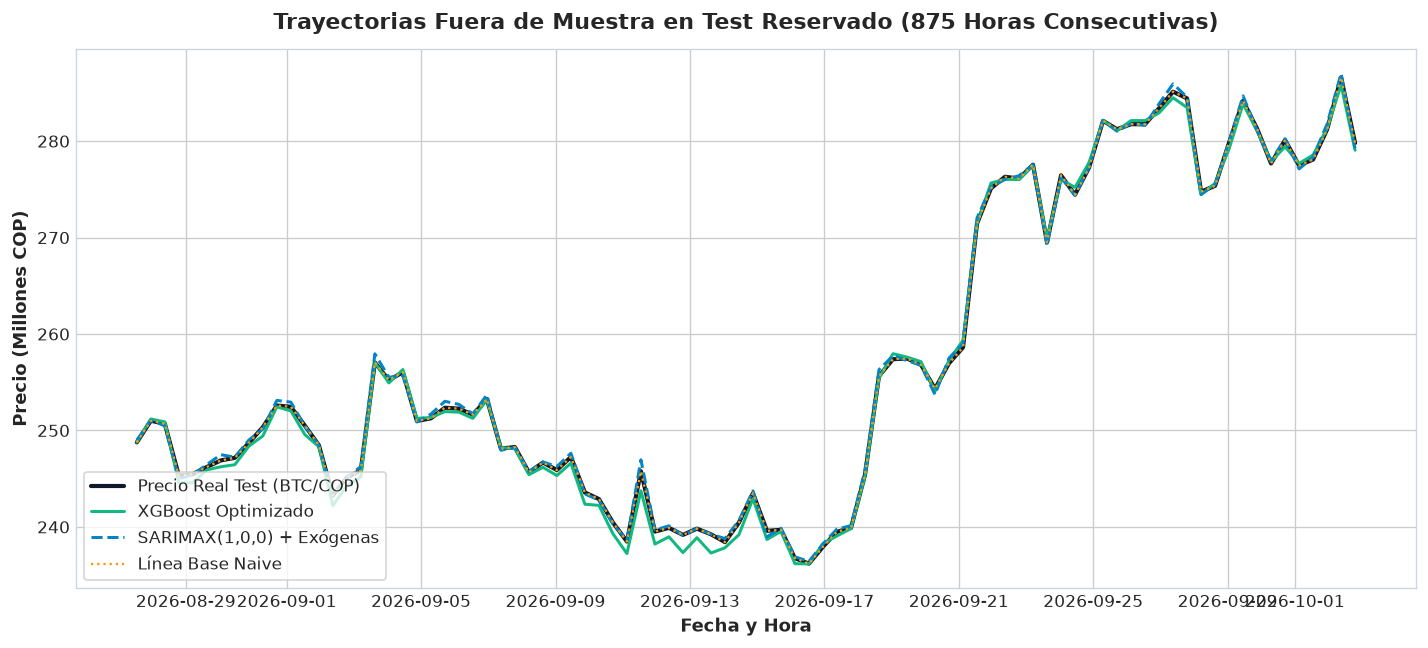

In [11]:
sample_idx = range(0, len(test_btc), 10)
ts_s = test_btc['timestamp'].iloc[sample_idx]
y_real_s = test_btc['close_cop'].iloc[sample_idx] / 1e6
y_xgb_s = xgb_preds[sample_idx] / 1e6
y_sar_s = sarimax_price_preds[sample_idx] / 1e6
y_nai_s = naive_preds[sample_idx] / 1e6

plt.figure(figsize=(12, 5.5))
plt.plot(ts_s, y_real_s, color='#0f172a', lw=2.5, label='Precio Real Test (BTC/COP)')
plt.plot(ts_s, y_xgb_s, color='#10b981', lw=1.8, label='XGBoost Optimizado')
plt.plot(ts_s, y_sar_s, color='#0284c7', lw=1.8, ls='--', label='SARIMAX(1,0,0) + Exógenas')
plt.plot(ts_s, y_nai_s, color='#f59e0b', lw=1.4, ls=':', label='Línea Base Naive')
plt.title('Trayectorias Fuera de Muestra en Test Reservado (875 Horas Consecutivas)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Precio (Millones COP)', fontsize=11, fontweight='bold')
plt.xlabel('Fecha y Hora', fontsize=11, fontweight='bold')
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()